In [1]:
#Updated and Adapted from Lab 1 Calculations
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import glob

In [2]:
def correct_encoding(measured_image):
    return measured_image / 16 +1

In [3]:
#Creation of Difference Image
with fits.open('Lab2/bias/bias-0001.fit') as hdul_bias1, fits.open('Lab2/bias/bias-0002.fit') as hdul_bias2:
    
    bias1_data = hdul_bias1[0].data
    bias2_data = hdul_bias2[0].data
    
    header = hdul_bias1[0].header

diff_data = bias1_data - bias2_data

hdu_diff = fits.PrimaryHDU(data=diff_data, header=header)
hdu_diff.writeto('difference_image.fits', overwrite=True)


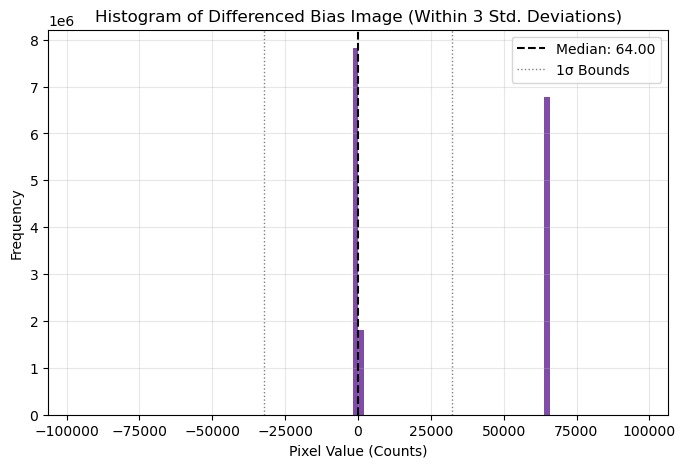

In [4]:
#Plotting of Difference Histogram
with fits.open('difference_image.fits') as hdul:
    diff_data = hdul[0].data

flat_data = diff_data.flatten()
flat_data = flat_data[~np.isnan(flat_data)]

median = np.median(flat_data)
std_dev = np.std(flat_data)

xmin = median - 3 * std_dev
xmax = median + 3 * std_dev

plt.figure(figsize=(8, 5))
plt.hist(flat_data, bins=100, range=(xmin, xmax), color='indigo', histtype='stepfilled', alpha=0.7)

plt.axvline(median, color='black', linestyle='dashed', linewidth=1.5, label=f'Median: {median:.2f}')
plt.axvline(median - std_dev, color='gray', linestyle='dotted', linewidth=1, label=f'1σ Bounds')
plt.axvline(median + std_dev, color='gray', linestyle='dotted', linewidth=1)

plt.title('Histogram of Differenced Bias Image (Within 3 Std. Deviations)')
plt.xlabel('Pixel Value (Counts)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [5]:
#Calculation of Read Noise

sigma_diff = np.std(diff_data)
read_noise = sigma_diff / np.sqrt(2)

In [6]:
sigma_diff

np.float64(32232.81712955645)

In [7]:
read_noise

np.float64(22792.043569055273)

In [8]:
#Bias Image Calculations
bias_files = glob.glob('Lab2/bias/*.fit')

#Correcting each bias image
corrected_array = []
for bias_path in bias_files:
    with fits.open(bias_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            foo.data = corrected_image
            corrected_array.append(foo.data)

Text(0.5, 1.0, 'Average Bias Image: QHY 163M CMOS')

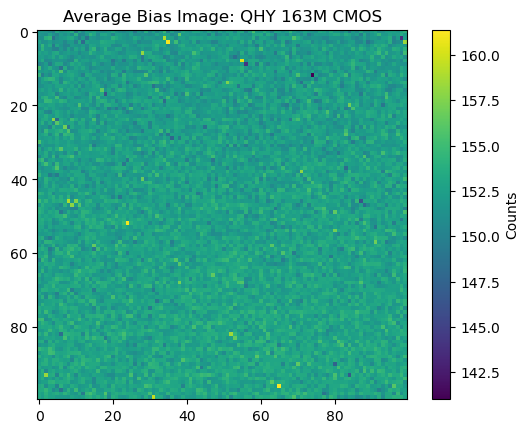

In [9]:
#Taking the average/median of the average of the now corrected images
bias_array = np.array(corrected_array)
bias_avg = np.mean(bias_array, axis=0)
bias_avg_median = np.median(bias_avg)

plt.imshow(bias_avg[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Bias Image: QHY 163M CMOS')

Text(0.5, 1.0, 'Average Bias Image: QHY 163M CMOS')

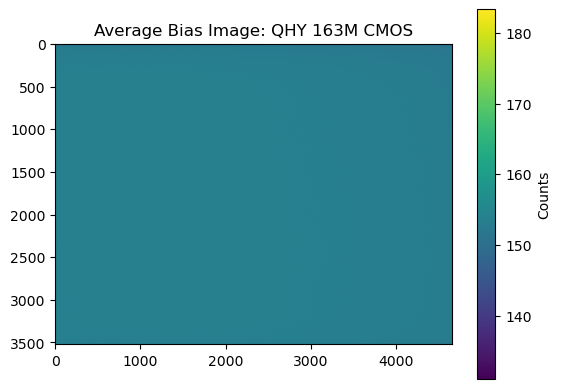

In [10]:
plt.imshow(bias_avg)
plt.colorbar(label='Counts')
plt.title('Average Bias Image: QHY 163M CMOS')


In [11]:
bias_avg_median

np.float64(153.7)

Text(0.5, 1.0, 'Average Dark Image: QHY 163M CMOS')

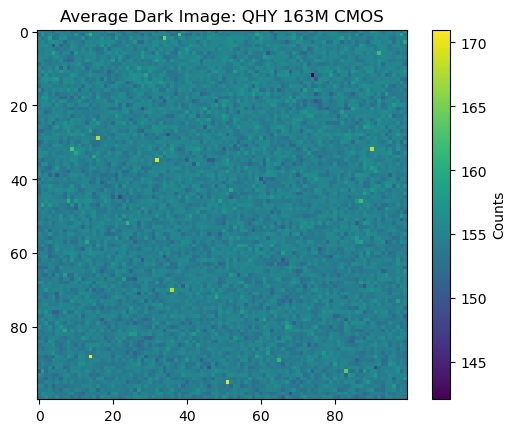

In [12]:
#Dark Image Calculations(Time 1)
dark1_files = glob.glob('Lab2/Darks10/*.fit')

#Correcting each dark image
corrected_array2 = []
for dark_path in dark1_files:
    with fits.open(dark_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            foo.data = corrected_image
            corrected_array2.append(foo.data)

#Taking the average/median of the average of the now corrected images
dark1_array = np.array(corrected_array2)
dark1_avg = np.mean(dark1_array, axis=0)
dark1_avg_median = np.median(dark1_avg)

plt.imshow(dark1_avg[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Dark Image: QHY 163M CMOS')

Text(0.5, 1.0, 'Average Dark Image: QHY 163M CMOS')

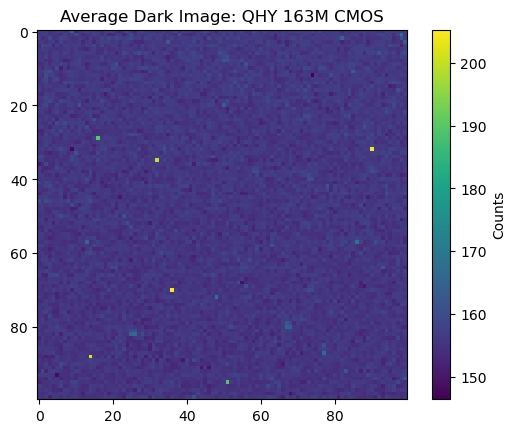

In [13]:
#Dark Image Calculations(Time 2)
dark2_files = glob.glob('Lab2/Darks30/*.fit')

#Correcting each dark image
corrected_array3 = []
for dark_path in dark2_files:
    with fits.open(dark_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            foo.data = corrected_image
            corrected_array3.append(foo.data)

#Taking the average/median of the average of the now corrected images
dark2_array = np.array(corrected_array3)
dark2_avg = np.mean(dark2_array, axis=0)
dark2_avg_median = np.median(dark2_avg)

plt.imshow(dark2_avg[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Dark Image: QHY 163M CMOS')

In [14]:
#Dark Image Calculations(Time 3)
#dark3_files = glob.glob('Lab1/dark_time-3/*.fit')

#Correcting each dark image
#corrected_array4 = []
#for dark_path in dark3_files:
    #with fits.open(dark_path, mode='update') as foo:
        #measured_image = foo[0].data

        #if measured_image is not None:
            #corrected_image = correct_encoding(measured_image)
            #foo.data = corrected_image
            #corrected_array4.append(foo.data)

#Taking the average/median of the average of the now corrected images
#dark3_array = np.array(corrected_array4)
#dark3_avg = np.mean(dark3_array, axis=0)
#dark3_avg_median = np.median(dark3_avg)

#plt.imshow(dark3_avg[0:100, 0:100])
#plt.colorbar(label ='Counts')
#plt.title('Average Dark Image: QHY 163M CMOS')

Text(0.5, 1.0, 'Average Normalized Twilight Flat: QHY 163M CMOS')

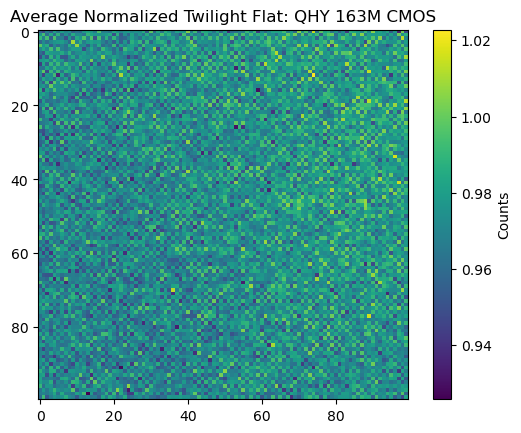

In [15]:
#Twilight Flat Calculations(
flat_files = glob.glob('Lab2/select_flats/*.fit')

#Correcting and normalizing each flat image
normal_stack = []
for flat_path in flat_files:
    with fits.open(flat_path, mode='update') as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
            z_i = corrected_image - bias_avg
            z_i_med = np.median(z_i)
            z_i_normal = z_i / z_i_med
            normal_stack.append(z_i_normal)

#Combining all corrected and normalized flats
final_normal_twi = np.median(normal_stack, axis=0)

plt.imshow(final_normal_twi[0:100, 0:100])
plt.colorbar(label ='Counts')
plt.title('Average Normalized Twilight Flat: QHY 163M CMOS')

In [16]:
#Creation of Calibrated Science Image For Loop 1 (PiPeg 1)
PiPeg_files = glob.glob('Lab2/PiPeg/*.fit')

for index, PiPeg_path in enumerate(PiPeg_files):
    with fits.open(PiPeg_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_1 = (S_i - d - b) / flat
    output_name = f"PiPeg_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_1)
    hdu.writeto(output_name, overwrite=True)


In [17]:
#Load a corrected file and view corrected image to check process
with fits.open('PiPeg_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

<function matplotlib.pyplot.show(close=None, block=None)>

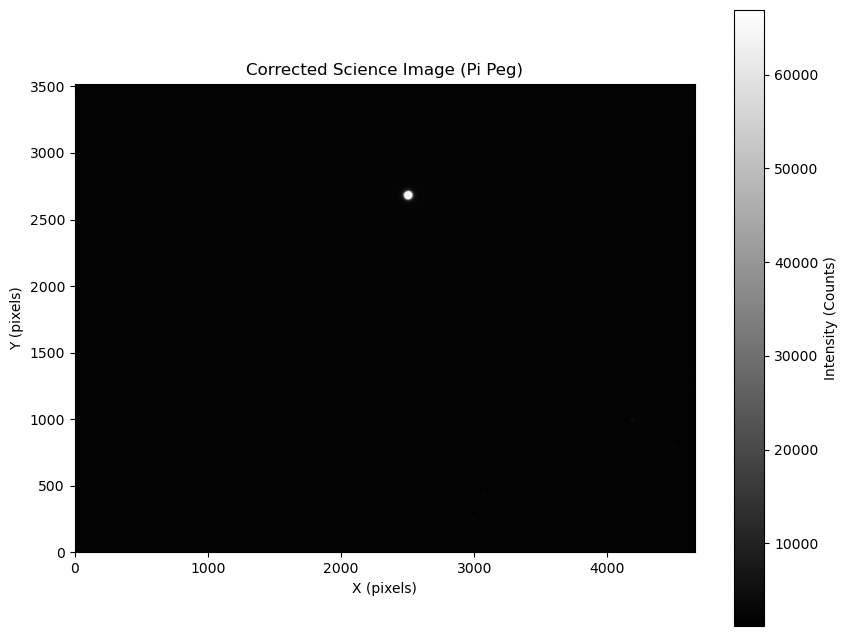

In [18]:
plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (Pi Peg)')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

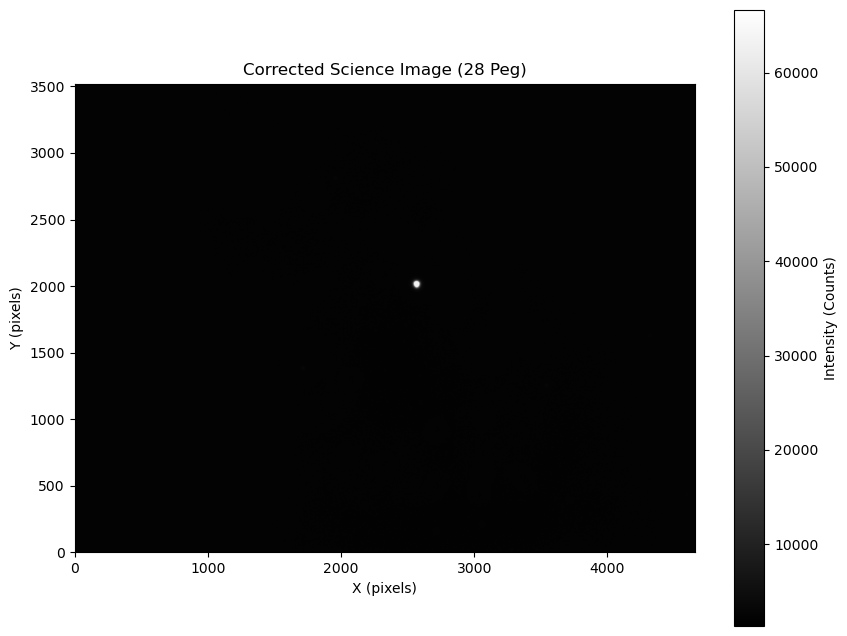

In [19]:
#Creation of Calibrated Science Image For Loop 2 (28 Peg 1)
TEPeg_files = glob.glob('Lab2/TEPeg/*.fit')

for index, TEPeg_path in enumerate(TEPeg_files):
    with fits.open(TEPeg_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"28Peg_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('28Peg_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (28 Peg)')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

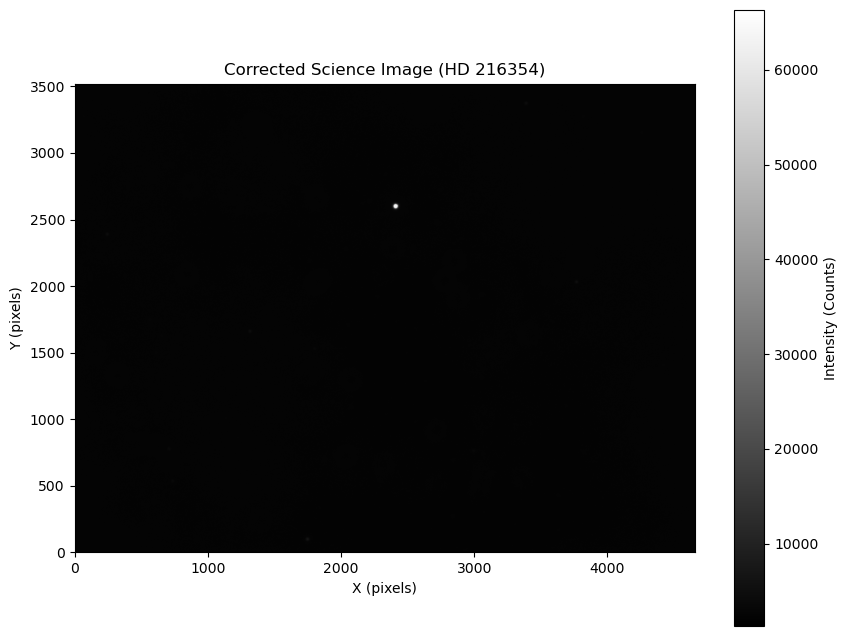

In [20]:
#Creation of Calibrated Science Image For Loop 3 (HD216 1)
HD216_files = glob.glob('Lab2/HD216/*.fit')

for index, HD216_path in enumerate(HD216_files):
    with fits.open(HD216_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark2_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"HD216_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('HD216_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (HD 216354)')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

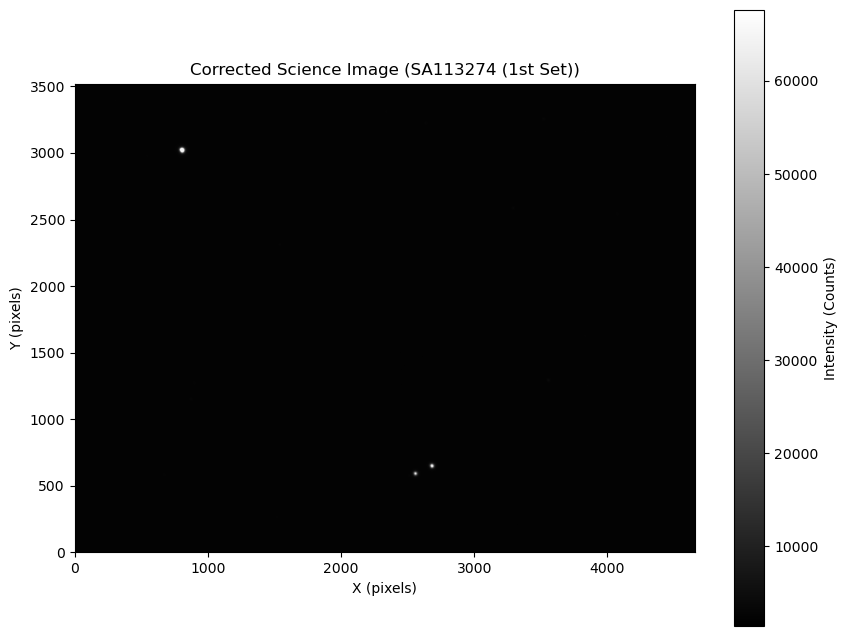

In [21]:
#Creation of Calibrated Calibrator Image For Loop 1 (SA113 (1st))
SA113_1st_files = glob.glob('Lab2/SA113-1st/*.fit')

for index, SA113_1st_path in enumerate(SA113_1st_files):
    with fits.open(SA113_1st_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"SA113_1st_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('SA113_1st_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (SA113274 (1st Set))')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

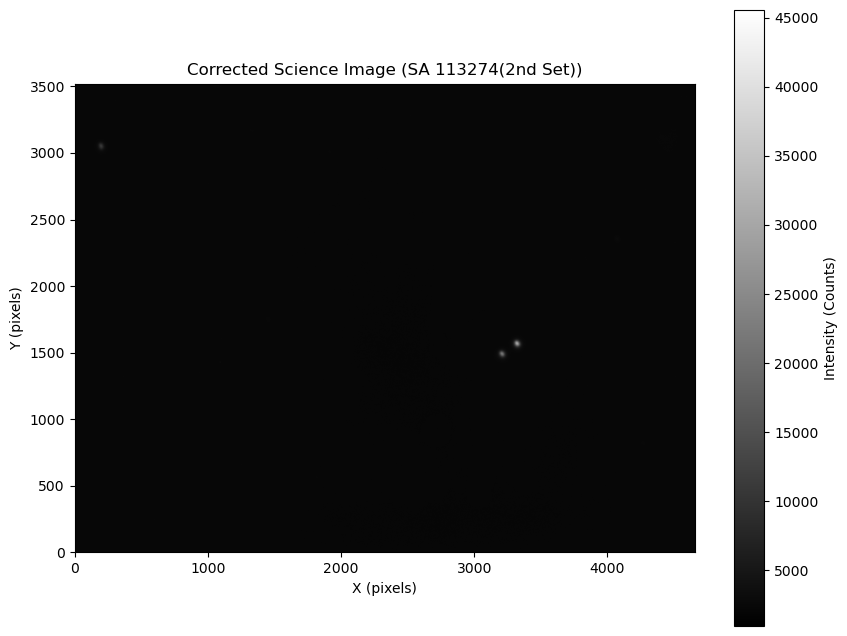

In [22]:
#Creation of Calibrated Calibrator Image For Loop 2 (SA113 (2nd))
SA113_2nd_files = glob.glob('Lab2/SA113-2nd/*.fit')

for index, SA113_2nd_path in enumerate(SA113_2nd_files):
    with fits.open(SA113_2nd_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark1_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"SA113_2nd_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('SA113_2nd_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (SA 113274(2nd Set))')

plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

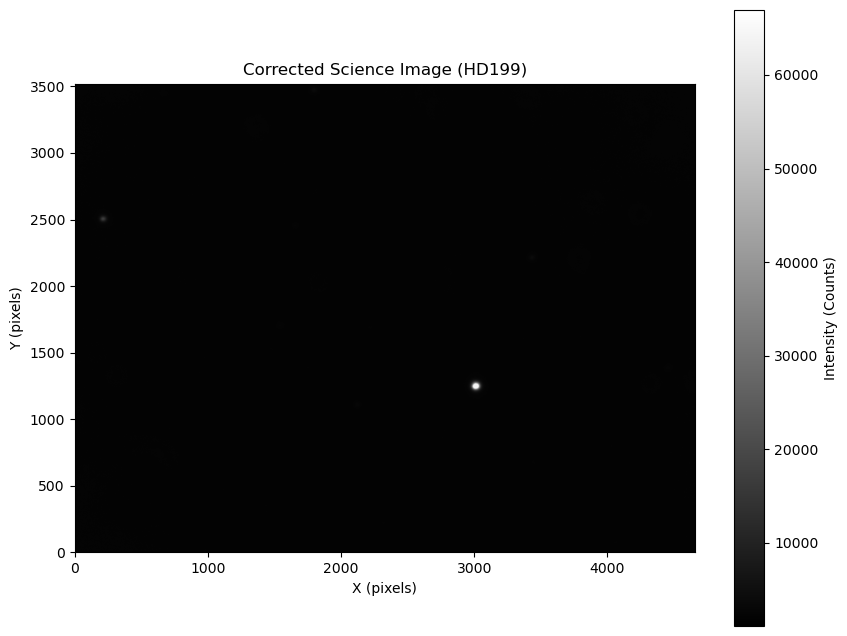

In [23]:
#Creation of Calibrated Calibrator Image For loop 3 (HD199)
HD199_files = glob.glob('Lab2/HD199/*.fit')

for index, HD199_path in enumerate(HD199_files):
    with fits.open(HD199_path) as hdul:
        S_i = hdul[0].data.astype(float)
        
        d = dark2_avg
        
        b = bias_avg
        
        flat = final_normal_twi

    calibrated_data_2 = (S_i - d - b) / flat
    output_name = f"HD199_corrected_{index}.fits"
    hdu = fits.PrimaryHDU(calibrated_data_2)
    hdu.writeto(output_name, overwrite=True)


with fits.open('HD199_corrected_0.fits') as hdul:
    data = hdul[0].data.astype(float)

plt.figure(figsize=(10,8))
img = plt.imshow(data, cmap = 'grey', origin='lower')
plt.xlabel('X (pixels)')
plt.ylabel('Y (pixels)')
plt.colorbar(img, label = 'Intensity (Counts)')
plt.title('Corrected Science Image (HD199)')

plt.show

In [24]:
#Start of CCD Gain Procedure
from astropy.io import fits

def load_fits_file(file_path):
    """Loads a FITS file containing a single dataset.
    """
    with fits.open(file_path) as hdul:
        hdu = hdul[0] if hdul[0].data is not None else hdul[1]
        return hdu.data.copy(), hdu.header.copy()

In [25]:
first_twilight = "Lab2/select_flats/twilightFlats_oct15-0001.fit"
image_data, header_info = load_fits_file(first_twilight)
np.mean(image_data)

np.float64(31821.92489623398)

In [26]:
last_twilight = "Lab2/select_flats/twilightFlats_oct15-0100.fit"
image_data, header_info = load_fits_file(last_twilight)
np.mean(image_data)

np.float64(3366.7724699532246)

In [27]:
#Chosen Levels
#30000
#25000
#20000
#15000
#10000
#7500
#5000
#3366

In [28]:
#Create bias corrected flats
flat_files = glob.glob('Lab2/select_flats/*.fit')
for index, flat_path in enumerate(flat_files):
    with fits.open(flat_path,) as foo:
        measured_image = foo[0].data

        if measured_image is not None:
            corrected_image = correct_encoding(measured_image)
        output_name = f"twilightflat__oct15_{index}.fits"
    hdu = fits.PrimaryHDU(corrected_image)
    hdu.writeto(output_name, overwrite=True)

In [29]:
def match_mean_signals(image_a, image_b, subarray_slices):
    """
    Measures the mean signal in subarrays of two images, calculates their ratio,
    and scales image B to match the mean signal level of image A.
    
    Parameters:
    -----------
    image_a : ndarray
        The reference image (Image A).
    image_b : ndarray
        The image to be scaled (Image B).
    subarray_slices : range of pixels for the subarray
        Format: (slice(y_start, y_end), slice(x_start, x_end)).
    """
    sub_a = image_a[subarray_slices]
    sub_b = image_b[subarray_slices]
        
    FA = np.mean(sub_a)
    FB = np.mean(sub_b)
        
    r = FA / FB
    image_b_scaled = image_b * r
    
    return image_b_scaled, r, FA


In [30]:
#Level 1
data_var = []
data_FA = []
twi_1st_lvl1 = "twilightflat__oct15_0.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_1.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [31]:
#Level 2
twi_1st_lvl1 = "twilightflat__oct15_7.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_8.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [32]:
#Level 3
twi_1st_lvl1 = "twilightflat__oct15_14.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_15.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [33]:
#Level 4
twi_1st_lvl1 = "twilightflat__oct15_23.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_24.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [34]:
#Level 5
twi_1st_lvl1 = "twilightflat__oct15_34.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_35.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [35]:
#Level 6
twi_1st_lvl1 = "twilightflat__oct15_46.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_47.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [36]:
#Level 7
twi_1st_lvl1 = "twilightflat__oct15_73.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_74.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [37]:
#Level 8
twi_1st_lvl1 = "twilightflat__oct15_98.fits"
image_data_1, header_info_1 = load_fits_file(twi_1st_lvl1)

twi_2nd_lvl1 = "twilightflat__oct15_99.fits"
image_data_2, header_info_2 = load_fits_file(twi_2nd_lvl1)

image_b_scaled, r, FA = match_mean_signals(image_data_1, image_data_2, (slice(0,75), slice(0,75)))

diff_image = image_data_1 - image_b_scaled
diff_subarray = diff_image[0:75, 0:75]
diff_var = np.var(diff_subarray)
data_var.append(diff_var)
data_FA.append(FA)

In [38]:
data_var_A = data_var/ np.sqrt(2)

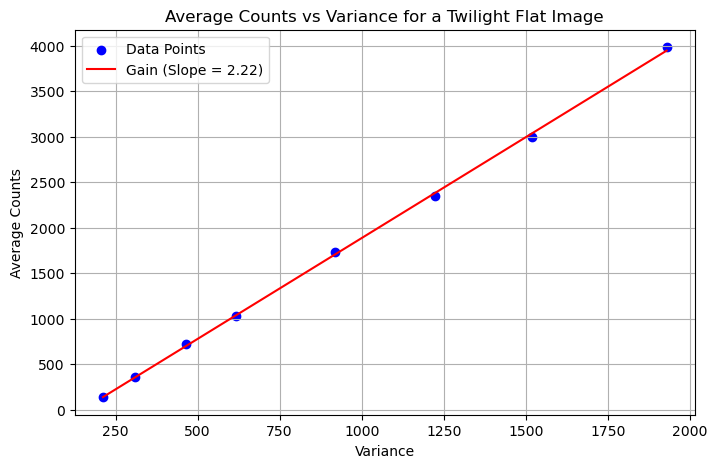

In [39]:
#Generation of least squares fitting coefficients and creation of Least Squares plot
matrix = np.column_stack((data_FA, data_var_A))
x = matrix[:, 0]
y = matrix[:, 1]

slope, intercept = np.polyfit(x, y, 1)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color="b", label="Data Points")

plt.plot(x, slope * x + intercept, color="r", label=f"Gain (Slope = {slope:.2f})")

plt.title("Average Counts vs Variance for a Twilight Flat Image")
plt.xlabel("Variance")
plt.ylabel("Average Counts")
plt.legend()
plt.grid(True)
plt.show()

In [40]:
#Calculation of uncertainty in gain
g = 2.22 #According to least squares fitting
Nadu = np.array(data_FA)
Ne = g * Nadu
sigma_e = np.sqrt(Ne)
#Individual Uncertainties
sigma_g_i = sigma_e / Nadu

#Final Uncertainty (Inverse-Variance Weighted)
sum_Nadu = np.sum(Nadu)
sum_Ne = np.sum(Ne)
sigma_g_tot = np.sqrt(sum_Ne) / sum_Nadu

In [41]:
sigma_g_tot

np.float64(0.01756718000182904)

In [42]:
#Instrumental Magnitude

In [43]:
#Provided Helper Functions
def implot(image,figsize=(15,13),cmap='gray_r',scale=0.5,colorbar=False,header=None,wcs=None,**kwargs):
    '''
    Plot an astronomical image, setting default options and easy tweaking of parameters
    This function is directly from the Yale Astro 330 course book by Imad Pasha and Marla Geha (2021 and following).    
    Parameters
    ----------
    image: array_like
        2D array containing an astronomical image to be plotted. Cutouts should be input as cutout.data.
    figsize: tuple, optional
        figure size to use. Default: (15,13)
    cmap: str, optional
        Colormap to use for the image. Default: 'gray_r'
    scale: float, optional
        By default, function will scale image to some number of standard deviations about the mean pixel value. Scale sets this number (or fraction). Default: 0.5.
    colorbar: bool, optional
        Whether to add a colorbar or not. Default: False
    header: dict, optional
        If input, function will attempt to create a WCS object from header and plot in celestial coordinates. Default: None
    wcs: WCS object
        If input, the function will plot using a projection set by the WCS. Default: None
    **kwargs
        Additional arguments are passed to matplotlib plotting commands. Currently supported: vmin, vmax.
        
    Returns
    -------
    fig, ax
        figure and axes objects containing currently plotted data.
    '''
    fig, ax = plt.subplots(figsize=figsize)
    mu = np.mean(image)
    s = np.std(image)
    dvmin = mu - scale*s
    dvmax = mu + scale*s
    if all(['vmin','vmax']) in kwargs.keys():
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=kwargs['vmin'],vmax=kwargs['vmax'])
    elif 'vmin' in kwargs.keys():
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=kwargs['vmin'],vmax=dvmax)
    elif 'vmax' in kwargs.keys():
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=dvmin,vmax=kwargs['vmax'])
    else:
        im = ax.imshow(image,origin='lower',cmap=cmap,vmin=dvmin,vmax=dvmax)
    if colorbar:
        cbar = plt.colorbar(im,ax=ax)
    return fig, ax

In [44]:
%matplotlib tk

In [45]:
#Copied code to identify center and width of star in each science image
import sys 
import matplotlib.pyplot as plt
import lab2_helper_functions as l2


# Enter your file name from the command line as a string.
filename = "Lab2/SA113-2nd/SA113_2nd_corrected_0.fits"
# Alt: set your filename as a string
#filename='/path/to/file/star.fits'

# Default value is set to 1/2 of each dimension.
center=[2328, 1761]

# Load fits data and header
foo = fits.open(filename)
my_data = foo[0].data
my_header = foo[0].header
foo.close()


print("Click anywhere on the image to place a star and print coordinates.")
print("Press any key to close plot")

def on_click(event):
    print('Your current coords are ')
    print(f' coords {event.xdata} {event.ydata}')
    ax.plot(event.xdata,event.ydata,'*',ms='5')

def on_press(event):
        plt.close()

# Plot fits data and a pink circle, showing where the center point of graph is.
fig, ax = l2.implot(my_data,figsize=[10,7])
plt.connect('button_press_event', on_click)
plt.connect('key_press_event', on_press)
ax.plot(center[0],center[1],'o', color='None', mec='m',ms=10,alpha=0.8)
plt.show()

Click anywhere on the image to place a star and print coordinates.
Press any key to close plot


In [46]:
#Convolving with the 2D Gaussian PSF
import numpy as np
from scipy.signal import convolve2d


def phot(data, centroid_x, centroid_y, sigma_x, sigma_y, window):
  """
    Evaluates a 2D Gaussian PSF model over a small window of data, convolves 
    it with the window, and sums the result to compute PSF photometry flux.

    Parameters
    ----------
    data :The full 2D image array containing pixel counts.
    centroid_x : The x-coordinate (column) of the source center.
    centroid_y : The y-coordinate (row) of the source center.
    sigma_x : The standard deviation (width) of the 2D Gaussian along the x-axis.
    sigma_y : The standard deviation (width) of the 2D Gaussian along the y-axis.
    window : The half-width of the square cutout box (in pixels) centered on the source.

    Returns
    -------
    model :The normalized 2D Gaussian PSF model evaluated on the cutout grid.
    psf_convolve : The 2D convolution of the data cutout with the PSF model.
    psf_flux :The total summed flux in counts across the convolved window.
    """
  # Define integer bounding box for the window around the centroid
  x_center = int(np.round(centroid_x))
  y_center = int(np.round(centroid_y))

  x_min = max(0, x_center - window)
  x_max = min(data.shape[1], x_center + window + 1)
  y_min = max(0, y_center - window)
  y_max = min(data.shape[0], y_center + window + 1)

  # Extract the small window of data
  sub_data = data[y_min:y_max, x_min:x_max]

  # Create a coordinate grid matching the sub_data cutout
  y_grid, x_grid = np.mgrid[y_min:y_max, x_min:x_max]

  # Evaluate the 2D Gaussian PSF model
  norm = 1.0 / (2.0 * np.pi * sigma_x * sigma_y)
  exponent = -(
      ((x_grid - centroid_x) ** 2) / (2.0 * sigma_x**2)
      + ((y_grid - centroid_y) ** 2) / (2.0 * sigma_y**2)
  )
  model = norm * np.exp(exponent)

  # Ensure the discrete model is normalized to sum to 1 over the window
  model /= np.sum(model)

  # Convolve the model with the window of data
  # mode='same' keeps the output array the exact same shape as sub_data
  psf_convolve = convolve2d(sub_data, model, mode='same', boundary='symm')

  # Sum the resulting convolution to get total flux in counts
  psf_flux = np.sum(psf_convolve)

  return model, psf_convolve, psf_flux


In [47]:
#Plotting data with contours from model
def plot_psf(data, model, centroid_x, centroid_y, window, star):
  """
    Plots the windowed image data with contour lines from the PSF model overlaid.

    Parameters
    ----------
    data :The full 2D image array containing pixel counts.
    model : The 2D Gaussian PSF model returned by `phot()`.
    centroid_x : The x-coordinate (column) of the source center.
    centroid_y : The y-coordinate (row) of the source center.
    window : The half-width of the square cutout box (in pixels) used in `phot()`.
    levels : Number of contour levels or specific contour values to plot (default is 5).
    """
  # Match the exact cutout coordinates used in phot()
  x_center = int(np.round(centroid_x))
  y_center = int(np.round(centroid_y))

  x_min = max(0, x_center - window)
  x_max = min(data.shape[1], x_center + window + 1)
  y_min = max(0, y_center - window)
  y_max = min(data.shape[0], y_center + window + 1)

  sub_data = data[y_min:y_max, x_min:x_max]
  y_grid, x_grid = np.mgrid[y_min:y_max, x_min:x_max]

  peak = np.max(model)
  levels = peak * np.array([.1, .3, .5, .7, .9])

  fig, ax = plt.subplots(figsize=(6, 5))

  # Plot the windowed data using pixel coordinates
  im = ax.imshow(
      sub_data,
      origin='lower',
      cmap='viridis',
      extent=[x_min - 0.5, x_max - 0.5, y_min - 0.5, y_max - 0.5],
  )
  plt.colorbar(im, ax=ax, label='Counts')

  # Overlay the PSF model contours
  ax.contour(x_grid, y_grid, model, levels=levels, colors='white', linewidths=1.5)

  # Mark the exact sub-pixel centroid
  ax.plot(
      centroid_x,
      centroid_y,
      marker='+',
      color='red',
      markersize=10,
      label='Centroid',
  )

  ax.set_title(f'Windowed Data with PSF Model Contours of {star}')
  ax.set_xlabel('X (pixels)')
  ax.set_ylabel('Y (pixels)')
  ax.legend(loc='upper right')
  plt.tight_layout()
  plt.show()
  #plt.savefig(f"Contour Plot of {star}")

In [48]:
#Background Subtraction
def psf_sky_subtract(data, model, psf_convolve, sky_x, sky_y, window):
  """
    Recenters onto a blank sky region, convoles with the PSF model to find N_sky, and subtracts from star to get net f
    Parameters
    ----------
    data :The full 2D image array containing pixel counts.
    model :The normalized 2D Gaussian PSF model returned by phot().
    psf_convolve : The 2D convolution of the star's data cutout with the PSF model returned by phot().
    sky_x : The x-coordinate (column) of the center of a blank sky region.
    sky_y : The y-coordinate (row) of the center of a blank sky region.
    window : The half-width of the square cutout box (in pixels) used in `phot()`.

    Returns
    -------
    n_sky :Median sky counts per pixel in the convolved blank sky aperture.
    n_tot_sky :Total sky counts across all n pixels in the aperture (n * n_sky).
    net_flux : The net sky-subtracted stellar flux in counts (N_net,*).
    """
  ny, nx = data.shape

  x_center = int(np.round(sky_x))
  y_center = int(np.round(sky_y))

  x_min = max(0, x_center - window)
  x_max = min(nx, x_center + window + 1)
  y_min = max(0, y_center - window)
  y_max = min(ny, y_center + window + 1)

  sky_sub_data = data[y_min:y_max, x_min:x_max]

  sky_convolve = convolve2d(sky_sub_data, model, mode='same', boundary='symm')
    
  n_sky = np.median(sky_convolve)
  n_pixels = psf_convolve.size
  n_tot_sky = n_pixels * n_sky
  net_flux = np.sum(psf_convolve - n_sky)

  return n_sky, n_tot_sky, net_flux

In [49]:
#Calculation of SNR
def compute_snr(net_flux, n_sky, n_pix, gain, read_noise,):
  """
    Computes the Signal-to-Noise Ratio (SNR) using the CCD equation.

    Parameters
    ----------
    net_flux : Net sky-subtracted stellar flux in counts/ADU (N_net,*).
    n_sky : Median sky background counts per pixel in ADU (N_sky).
    n_pix : Total number of pixels in the aperture (e.g., psf_convolve.size).
    gain : Detector gain in electrons per ADU (e-/ADU).
    read_noise : Detector read noise in electrons per pixel (e-). 
    Returns
    -------
    snr : The Signal-to-Noise Ratio of the detection.
    flux_err : The 1-sigma uncertainty in the net stellar flux (in counts/ADU).
    """
  # Convert counts (ADU) to electrons (e-)
  signal_e = gain * net_flux
  sky_e = gain * n_sky

  # Total variance in electrons^2 across the aperture
  variance_e = signal_e + n_pix * (sky_e + read_noise**2)

  # Total noise in electrons
  noise_e = np.sqrt(variance_e)

  # SNR and 1-sigma flux uncertainty converted back to ADU
  snr = signal_e / noise_e
  flux_err = noise_e / gain

  return snr, flux_err


In [50]:
#Testing Ground for previous functions
data1, header = load_fits_file('Lab2/HD216/HD216_corrected_0.fits')
x_center = 2408
y_center = 2598
window = 50
model1, psf_convolve1, psf_flux1 = phot(data1, x_center, y_center, 20, 20, window)

plot_psf(data1, model1, x_center, y_center, window, "HD 216354")

In [51]:
#Aperture choice based off largest magnitude star, HD 216354, as other science stars will have higher SNRs for same aperture

In [52]:
n_sky, n_tot_sky, net_flux = psf_sky_subtract(data1, model1, psf_convolve1, 40, 40, window)

In [53]:
windows = range(5, 60, 5)
snr_list = []
n_pix_list = []

In [54]:
gain = g

for w in windows:
    model, psf_convolve, psf_flux = phot(data1, x_center, y_center, 20, 20, w)
    n_sky, n_tot_sky, net_flux = psf_sky_subtract(data1, model1, psf_convolve, 40, 40, w)
    n_pix = psf_convolve.size
    snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
    n_pix_list.append(n_pix)
    snr_list.append(snr)

In [55]:
def plot_snr_growth(n_pix_list, snr_list, highlight_peak=True):
  """
    Plots an SNR curve of growth (SNR vs. number of aperture pixels) and highlights the optimal aperture size where SNR peaks.

    Parameters
    ----------
    n_pix_list : Number of pixels in the aperture for each window size tested.
    snr_list : Measured Signal-to-Noise Ratio corresponding to each n_pix value.
    highlight_peak :If True, marks and annotates the maximum SNR point on the plot.
    """
  n_pix = np.asarray(n_pix_list)
  snr = np.asarray(snr_list)

  sort_idx = np.argsort(n_pix)
  n_pix = n_pix[sort_idx]
  snr = snr[sort_idx]

  fig, ax = plt.subplots(figsize=(7, 5))

  # Plot the growth curve
  ax.plot(n_pix, snr, marker='o', linestyle='-', color='royalblue', linewidth=2, markersize=6, label='SNR Growth Curve')

  # Highlight the optimal aperture (peak SNR)
  if highlight_peak and len(snr) > 0:
    max_idx = np.argmax(snr)
    best_npix = n_pix[max_idx]
    best_snr = snr[max_idx]

    ax.plot(best_npix, best_snr, marker='*', color='crimson', markersize=14, zorder=5, label=f'Peak SNR: {best_snr:.1f} ({best_npix} px)')
    ax.axvline(best_npix, color='crimson', linestyle='--', alpha=0.5)

  ax.set_title('Growth Curve: SNR vs. Aperture Area')
  ax.set_xlabel('Number of Pixels ($n_{\\mathrm{pix}}$)')
  ax.set_ylabel('Signal-to-Noise Ratio (SNR)')
  ax.grid(True, linestyle=':', alpha=0.7)
  ax.legend(loc='best')
  plt.tight_layout()
  plt.show()
  plt.savefig("SNR vs Npix Growth Curve")

In [56]:
plot_snr_growth(n_pix_list, snr_list)

In [57]:
ideal_window = ((np.sqrt(961))-1)/2
ideal_window

np.float64(15.0)

In [58]:
#Calculating Instrumental Magnitude
def calc_instrumental_mag(net_flux, snr, exp_time):
  """
    Calculates the instrumental magnitude and its 1-sigma uncertainty from net stellar counts and the CCD equation.

    Parameters
    ----------
    net_flux : Net sky-subtracted stellar flux in counts/ADU (N_net,*).
    snr : Signal-to-Noise Ratio computed from the CCD equation.
    exp_time :Exposure time in seconds

    Returns
    -------
    m_inst : Instrumental magnitude.
    m_err : 1-sigma uncertainty in the instrumental magnitude.
    """

  # Equation 3: Instrumental magnitude
  m_inst = -2.5 * np.log10(net_flux / exp_time)

  # Magnitude uncertainty propagated from CCD equation SNR
  m_err = (2.5 / np.log(10)) / snr

  return m_inst, m_err


In [59]:
#Plug in values for ideal aperture, data, and center for each science star
data1, header = load_fits_file('Lab2/HD216/HD216_corrected_0.fits')
x_center = 2408
y_center = 2598
window = 15

model1, psf_convolve1, psf_flux1 = phot(data1, x_center, y_center, 20, 20, window)

n_sky, n_tot_sky, net_flux = psf_sky_subtract(data1, model1, psf_convolve1, 40, 40, window)
n_pix = psf_convolve1.size
snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
exp_time = 30

m_inst_HD216, m_err_HD216 = calc_instrumental_mag(net_flux, snr, exp_time)

print(f"Instrumental Magnitude HD 216354: {m_inst_HD216:.2f} +/- {m_err_HD216:.2f} mag")

Instrumental Magnitude HD 216354: -15.55 +/- 0.01 mag


In [60]:
data1, header = load_fits_file('Lab2/PiPeg/PiPeg_corrected_0.fits')
x_center = 2503
y_center = 2678
window = 15

model1, psf_convolve1, psf_flux1 = phot(data1, x_center, y_center, 20, 20, window)

n_sky, n_tot_sky, net_flux = psf_sky_subtract(data1, model1, psf_convolve1, 40, 40, window)
n_pix = psf_convolve1.size
snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
exp_time = 10

m_inst_PiPeg, m_err_PiPeg = calc_instrumental_mag(net_flux, snr, exp_time)

print(f"Instrumental Magnitude Pi Peg: {m_inst_PiPeg:.2f} +/- {m_err_PiPeg:.2f} mag")

Instrumental Magnitude Pi Peg: -16.95 +/- 0.01 mag


In [61]:
data1, header = load_fits_file('Lab2/TEPeg/28Peg_corrected_0.fits')
x_center = 2565
y_center = 2013
window = 15

model1, psf_convolve1, psf_flux1 = phot(data1, x_center, y_center, 20, 20, window)

n_sky, n_tot_sky, net_flux = psf_sky_subtract(data1, model1, psf_convolve1, 40, 40, window)
n_pix = psf_convolve1.size
snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
exp_time = 10

m_inst_TEPeg, m_err_TEPeg = calc_instrumental_mag(net_flux, snr, exp_time)

print(f"Instrumental Magnitude 28 Peg: {m_inst_TEPeg:.2f} +/- {m_err_TEPeg:.2f} mag")

Instrumental Magnitude 28 Peg: -16.93 +/- 0.01 mag


In [62]:
#Calibration
def compute_offset_airmass(net_flux, snr, catalog_mag, exp_time, altitude_deg):
  """
    Computes the instrumental magnitude, airmass (sec z), and total photometric 
    offset C = m_cat - m_inst for a star
    Parameters
    ----------
    net_flux : Net sky-subtracted stellar counts (N_net,*).
    snr : Signal-to-Noise Ratio from compute_snr().
    catalog_mag : Known apparent catalog magnitude (m) of the standard star or Vega.
    exp_time : Exposure time (t) in seconds.
    altitude_deg : Target altitude (elevation) in degrees above the horizon

    Returns
    -------
    m_inst : Instrumental magnitude.
    m_err : 1-sigma uncertainty in instrumental magnitude (and C).
    sec_z : Airmass at the time of observation.
    C : Total photometric offset C = m_cat + 2.5 * log10(N / t).
    """

  # Calculate sec(z) from altitude
  zenith_rad = np.radians(90.0 - altitude_deg)
  sec_z = 1.0 / np.cos(zenith_rad)

  # Call existing instrumental magnitude function
  m_inst, m_err = calc_instrumental_mag(net_flux, snr, exp_time=exp_time)

  # Equation 9: C = m + 2.5 * log10(N/t) = m_cat - m_inst
  C = catalog_mag - m_inst

  return m_inst, m_err, sec_z, C


In [63]:
C_list = []
sec_z_list = []

In [64]:
#Use function to add to list of C and sec z values
#HD 199280
data2, header2 = load_fits_file('Lab2/HD199/HD199_corrected_0.fits')
x_center = 3017
y_center = 1240
window = 15


model2, psf_convolve2, psf_flux2 = phot(data2, x_center, y_center, 20, 20, window)

n_sky, n_tot_sky, net_flux = psf_sky_subtract(data2, model1, psf_convolve2, 40, 40, window)
n_pix = psf_convolve2.size
snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
exp_time = 30

m_inst_HD199, m_err_HD199, airmass_HD199, C_HD199 = compute_offset_airmass(net_flux, snr, 6.56, 10, 40)

print(f"Instrumental Magnitude HD 199280: {m_inst_HD199:.2f} +/- {m_err_HD199:.2f} mag")
print(f"Offset Value: {C_HD199:.2f}")
C_list.append(C_HD199)
sec_z_list.append(airmass_HD199)

Instrumental Magnitude HD 199280: -16.85 +/- 0.01 mag
Offset Value: 23.41


In [65]:
#1st Airmass of SA 113274 (Binary, Chosen Star SAO 127004)
data2, header2 = load_fits_file('Lab2/SA113-1st/SA113_1st_corrected_0.fits')
x_center = 2679
y_center = 651
window = 15


model2, psf_convolve2, psf_flux2 = phot(data2, x_center, y_center, 20, 20, window)

n_sky, n_tot_sky, net_flux = psf_sky_subtract(data2, model1, psf_convolve2, 40, 40, window)
n_pix = psf_convolve2.size
snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
exp_time = 10

m_inst_SAO004_1st, m_err_SAO004_1st, airmass_SAO004_1st, C_SAO004_1st = compute_offset_airmass(net_flux, snr, 8.88, 30, 33.54)

print(f"Instrumental Magnitude SAO 127004 (1st time): {m_inst_SAO004_1st:.2f} +/- {m_err_SAO004_1st:.2f} mag")
print(f"Offset Value: {C_SAO004_1st:.2f}")
C_list.append(C_SAO004_1st)
sec_z_list.append(airmass_SAO004_1st)

Instrumental Magnitude SAO 127004 (1st time): -15.07 +/- 0.01 mag
Offset Value: 23.95


In [66]:
#2nd Airmass of SA 113274 (Binary, Chosen Star SAO 127004)
data2, header2 = load_fits_file('Lab2/SA113-2nd/SA113_2nd_corrected_0.fits')
x_center = 3327
y_center = 1561
window = 15


model2, psf_convolve2, psf_flux2 = phot(data2, x_center, y_center, 20, 20, window)

n_sky, n_tot_sky, net_flux = psf_sky_subtract(data2, model1, psf_convolve2, 40, 40, window)
n_pix = psf_convolve2.size
snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
exp_time = 10

m_inst_SAO004_2nd, m_err_SAO004_2nd, airmass_SAO004_2nd, C_SAO004_2nd = compute_offset_airmass(net_flux, snr, 8.88, 30, 33.54)

print(f"Instrumental Magnitude SAO 127004 (2nd time): {m_inst_SAO004_2nd:.2f} +/- {m_err_SAO004_2nd:.2f} mag")
print(f"Offset Value: {C_SAO004_2nd:.2f}")
C_list.append(C_SAO004_2nd)
sec_z_list.append(airmass_SAO004_2nd)

Instrumental Magnitude SAO 127004 (2nd time): -14.40 +/- 0.02 mag
Offset Value: 23.28


In [67]:
#Airmass of SA 113274 (Binary, Chosen Star SAO 127005)
data2, header2 = load_fits_file('Lab2/SA113-1st/SA113_1st_corrected_0.fits')
x_center = 2555
y_center = 586
window = 15


model2, psf_convolve2, psf_flux2 = phot(data2, x_center, y_center, 20, 20, window)

n_sky, n_tot_sky, net_flux = psf_sky_subtract(data2, model1, psf_convolve2, 40, 40, window)
n_pix = psf_convolve2.size
snr, flux_err = compute_snr(net_flux, n_sky, n_pix, gain, read_noise)
exp_time = 10

m_inst_SAO005, m_err_SAO005, airmass_SAO005, C_SAO005 = compute_offset_airmass(net_flux, snr, 9.20, 30, 33.54)

print(f"Instrumental Magnitude SAO 127005: {m_inst_SAO005:.2f} +/- {m_err_SAO005:.2f} mag")
print(f"Offset Value: {C_SAO005:.2f}")
C_list.append(C_SAO005)
sec_z_list.append(airmass_SAO005)

Instrumental Magnitude SAO 127005: -14.78 +/- 0.01 mag
Offset Value: 23.98


In [68]:
#Using gathered airmasses and C values, plotting and using least squares to find ZP and k
def fit_and_plot(sec_z_list, C_list, star_names):
  """
    Fits C = ZP + k * sec(z) using Least Squares and plots C vs. airmass.

    Parameters
    ----------
    sec_z_list : Airmass values (sec z) for each standard star observation.
    C_list : Photometric offset values (C) for each observation.
    star_names : Labels for each observation to annotate points on the plot.

    Returns
    -------
    k : First-order atmospheric extinction coefficient (slope).
    k_err : 1-sigma uncertainty in k.
    zp : Photometric zero-point at zero airmass (intercept).
    zp_err : 1-sigma uncertainty in ZP.
    """
  x = np.asarray(sec_z_list, dtype=float)
  y = np.asarray(C_list, dtype=float)

  y_err = None
  params, cov = np.polyfit(x, y, deg=1, cov=True)

  k, zp = params
  k_err, zp_err = np.sqrt(np.diag(cov))

  # Plotting
  fig, ax = plt.subplots(figsize=(7.5, 5.5))

  ax.errorbar(x, y, yerr=y_err, fmt='o', color='navy', ecolor='gray', elinewidth=1.5, capsize=4, markersize=7, label='Standard Observations')

  for xi, yi, name in zip(x, y, star_names):
    ax.annotate(name, (xi, yi), textcoords='offset points', xytext=(6, 6), fontsize=9)

  # Plot the best-fit line extending back to sec(z) = 0 (to visualize ZP) or across data range
  x_fit = np.linspace(min(1.0, np.min(x) - 0.05), np.max(x) + 0.05, 100)
  y_fit = zp + k * x_fit

  fit_label = (f'Least Squares Fit: \ C = ({zp:.3f} ± {zp_err:.3f}) + ({k:.3f} ± {k_err:.3f})\\sec z$')
  ax.plot(x_fit, y_fit, color='crimson', linestyle='--', linewidth=2, label=fit_label)

  title_str = (f'Atmospheric Extinction Fit (V Band)')
  ax.set_title(title_str)
  ax.set_xlabel('Airmass ($\\sec z$)')
  ax.set_ylabel('Total Offset $C = m + 2.5\\log_{10}(N/t)$ (mag)')
  ax.grid(True, linestyle=':', alpha=0.7)
  ax.legend(loc='best')
  plt.tight_layout()
  plt.show()

  return k, k_err, zp, zp_err


In [69]:
star_list = ['HD 199280', 'SAO 127004 (1st)', 'SAO 127004 (2nd)', 'SAO 127005']
k, k_err, zp, zp_err = fit_and_plot(sec_z_list, C_list, star_list)
print(f'k value: {k:.4f} +/- {k_err:.4f} mag/airmass')
print(f'Zero-Point (ZP): {zp:.4f} +/- {zp_err:.4f} mag')

k value: 1.2870 +/- 1.8100 mag/airmass
Zero-Point (ZP): 21.4060 +/- 3.1672 mag


In [70]:
#Final Corrections
import math
def calibrate_magnitude(m_inst, altitude_deg, zp, k, zp_err, k_err, m_inst_err):
    """
    Calculates airmass and calibrates magnitude

    Parameters:
    m_inst: Instrumental magnitude of the star.
    altitude_deg: Altitude above the horizon in degrees (0 to 90).
    zp: Photometric Zero Point (ZP).
    k: First-order atmospheric extinction coefficient (mag/airmass).
    zp_err: 1-sigma uncertainty in ZP.
    k_err: 1-sigma uncertainty in k.
    m_inst_err: 1-sigma uncertainty in instrumental magnitude.

    Returns:
    tuple: (airmass, calibrated_magnitude, calibrated_magnitude_err)
    """
    # Convert altitude to zenith angle
    zenith_deg = 90.0 - altitude_deg
    zenith_rad = math.radians(zenith_deg)

    airmass = 1.0 / math.cos(zenith_rad)

    # Calculate Calibrated Magnitude
    m_cal = m_inst + zp - (k * airmass)

    # Propagate uncertainties
    # Formula: sigma_m = sqrt( sigma_m_inst^2 + sigma_ZP^2 + (X * sigma_k)^2 )
    variance = (m_inst_err ** 2) + (zp_err ** 2) + ((airmass * k_err) ** 2)
    m_cal_err = math.sqrt(variance)

    return airmass, m_cal, m_cal_err

In [71]:
#HD 216354
airmass_HD216, m_cal_HD216, m_cal_err_HD216 = calibrate_magnitude(m_inst_HD216, 58.38, zp, k, zp_err, k_err, m_err_HD216)
print(f'Calibrated Magnitude HD 216354: {m_cal_HD216:.3f} +/- {m_cal_err_HD216:.3f}')
#Pi Peg
airmass_PiPeg, m_cal_PiPeg, m_cal_err_PiPeg = calibrate_magnitude(m_inst_PiPeg, 62.10, zp, k, zp_err, k_err, m_err_PiPeg)
print(f'Calibrated Magnitude Pi Peg: {m_cal_PiPeg:.3f} +/- {m_cal_err_PiPeg:.3f}')
#28 Peg
airmass_TEPeg, m_cal_TEPeg, m_cal_err_TEPeg = calibrate_magnitude(m_inst_TEPeg, 53.18, zp, k, zp_err, k_err, m_err_TEPeg)
print(f'Calibrated Magnitude 28 Peg: {m_cal_TEPeg:.3f} +/- {m_cal_err_TEPeg:.3f}')

Calibrated Magnitude HD 216354: 4.349 +/- 3.814
Calibrated Magnitude Pi Peg: 2.997 +/- 3.772
Calibrated Magnitude 28 Peg: 2.870 +/- 3.891
